# 02 – Data Understanding & Data Quality Assessment (Milestone 3, N05)
Task 1–2 của đề P3. Raw được đọc **chỉ đọc** từ `P2/data/raw`. Script `src/profile_data.py` tạo `data/metadata/profiling_summary.json` và hình trong `reports/milestone3/figures/`.

In [1]:
import sys, json; sys.path.insert(0,'../src')
import pandas as pd
from config import *
import profile_data

# 1. Shape & schema của 7 bảng

In [2]:
for f in ['studentInfo','studentRegistration','assessments','studentAssessment','vle','courses']:
    df=pd.read_csv(RAW/f'{f}.csv',na_values=NA,nrows=3); print(f, list(df.columns))

studentInfo ['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']
studentRegistration ['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']
assessments ['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']
studentAssessment ['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']
vle ['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']
courses ['code_module', 'code_presentation', 'module_presentation_length']


# 2. Chạy profiling (cần chạy 03/prepare_data.py trước để có interim)

In [3]:
profile_data.main()

{
 "shape": {
  "studentInfo": {
   "rows_all": 32593,
   "rows_scope": 15671,
   "cols": 12
  },
  "studentRegistration": {
   "rows_all": 32593,
   "rows_scope": 15671,
   "cols": 5
  },
  "assessments": {
   "rows_all": 206,
   "rows_scope": 94,
   "cols": 6
  },
  "studentAssessment": {
   "rows_all": 173912,
   "rows_scope": null,
   "cols": 5
  },
  "vle": {
   "rows_all": 6364,
   "rows_scope": 3121,
   "cols": 6
  },
  "courses": {
   "rows_all": 22,
   "rows_scope": 8,
   "cols": 3
  }
 },
 "course_length": {
  "BBB-2013J": 268,
  "BBB-2014J": 262,
  "BBB-2013B": 240,
  "BBB-2014B": 234,
  "FFF-2013J": 268,
  "FFF-2014J": 269,
  "FFF-2013B": 240,
  "FFF-2014B": 241
 },
 "missing": {
  "studentInfo.imd_band": {
   "n": 430,
   "rate": 0.0274
  },
  "studentRegistration.date_registration": {
   "n": 20,
   "rate": 0.0013
  },
  "studentRegistration.date_unregistration": {
   "n": 10914,
   "rate": 0.6964
  },
  "assessments.date": {
   "n": 4,
   "rate": 0.0426
  },
  "studentAs

In [4]:
S=json.load(open(META/'profiling_summary.json'))
pd.DataFrame(S['missing']).T

,n,rate
studentInfo.imd_band,430.0,0.0274
studentRegistration.date_registration,20.0,0.0013
studentRegistration.date_unregistration,10914.0,0.6964
assessments.date,4.0,0.0426
studentAssessment.score,99.0,0.0010
vle.week_from,2109.0,0.6757
vle.week_to,2109.0,0.6757


In [5]:
pd.Series(S['orphans'])

studentAssessment_student_not_registered       0
registrations_without_any_vle               1957
registrations_without_vle_0_28              2486
active_d28_without_vle_0_28                  542
dtype: int64

In [6]:
pd.Series(S['validity'])

score_out_of_0_100                                                                    0
submitted_after_course_end                                                           72
unregistration_before_registration                                                    0
vle_date_min                                                                        -23
vle_date_max                                                                        269
vle_after_course_end                                                                  0
vle_week_from_missing_rate                                                        0.676
imd_band_levels                       [0-10%, 10-20%, 20-30%, 30-40%, 40-50%, 50-60%...
dtype: object

In [7]:
pd.DataFrame({'all':S['final_result_all']}).assign(share=lambda d:d['all']/d['all'].sum()).round(3)

,all,share
Pass,6055,0.386
Withdrawn,4791,0.306
Fail,3478,0.222
Distinction,1347,0.086


# 3. Hình


fig1_missingness.png


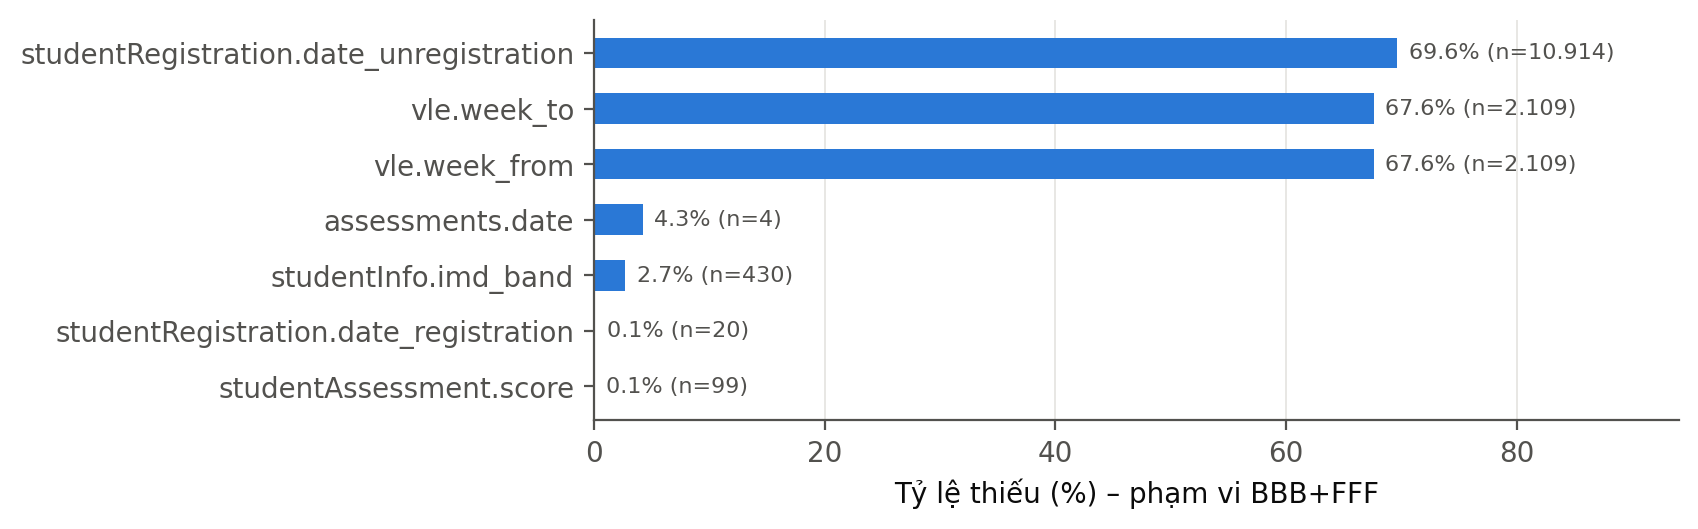

fig2_target_balance.png


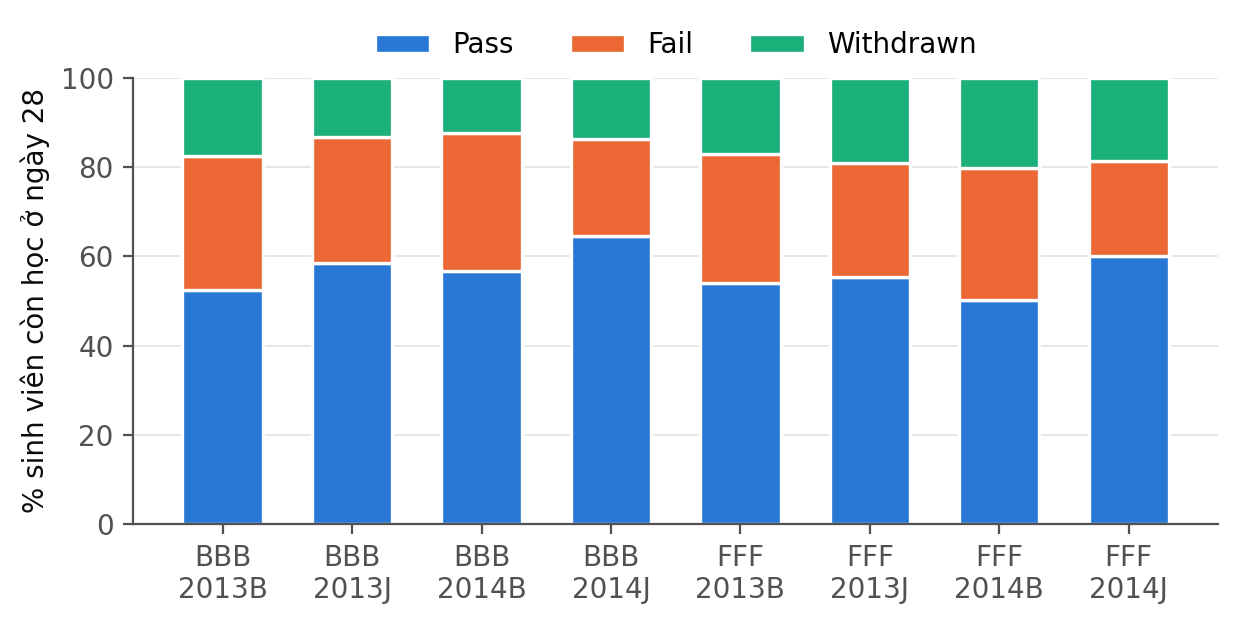

fig3_temporal_coverage.png


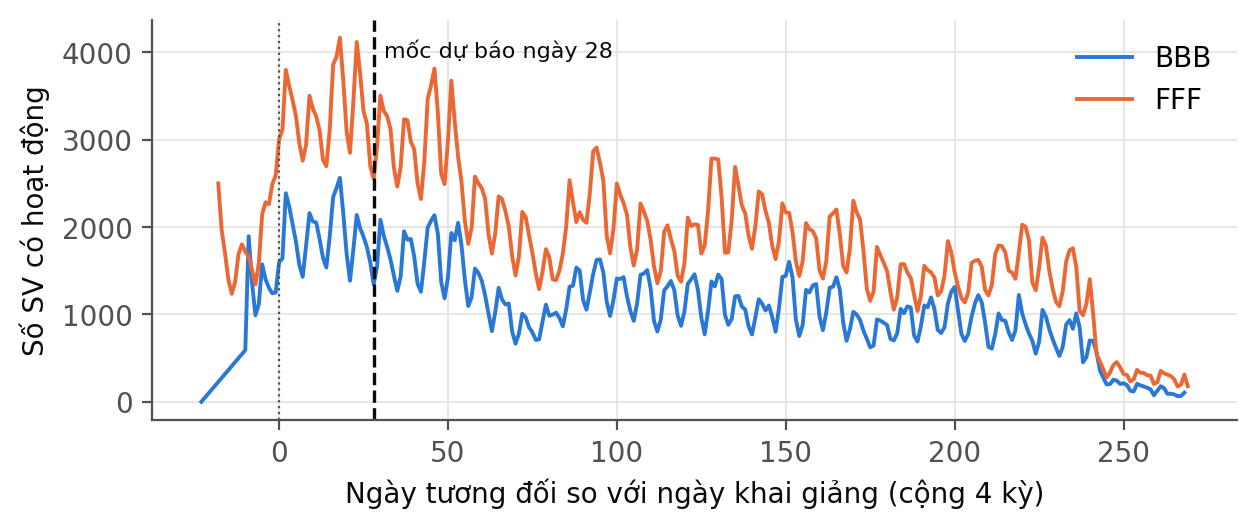

fig4_weekly_clicks_by_result.png


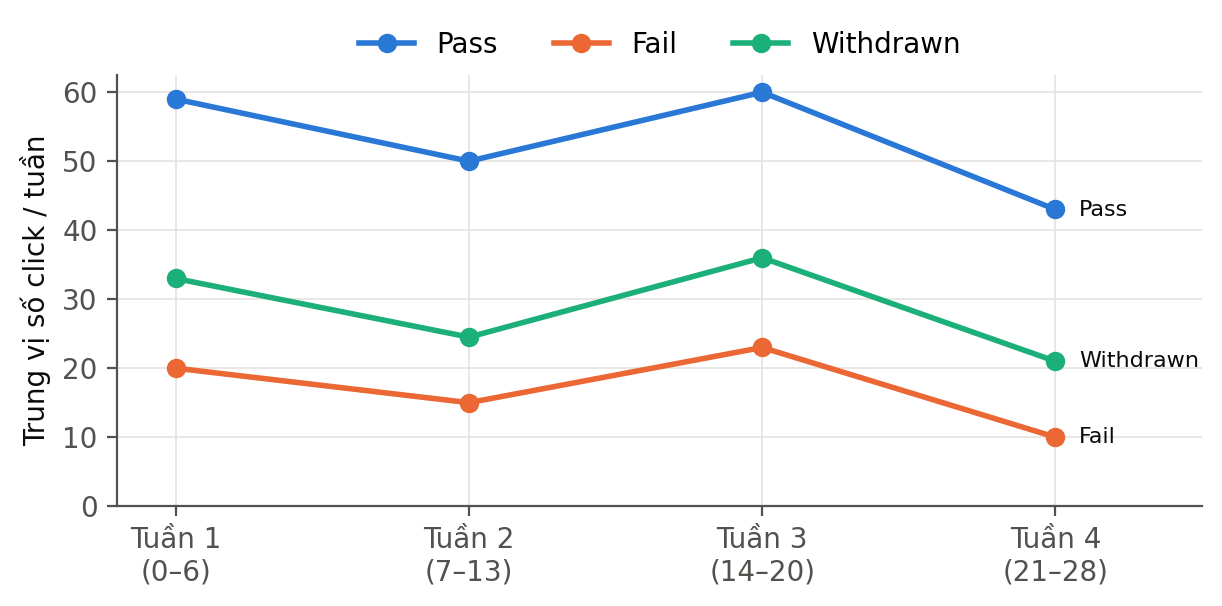

fig5_clicks_distribution.png


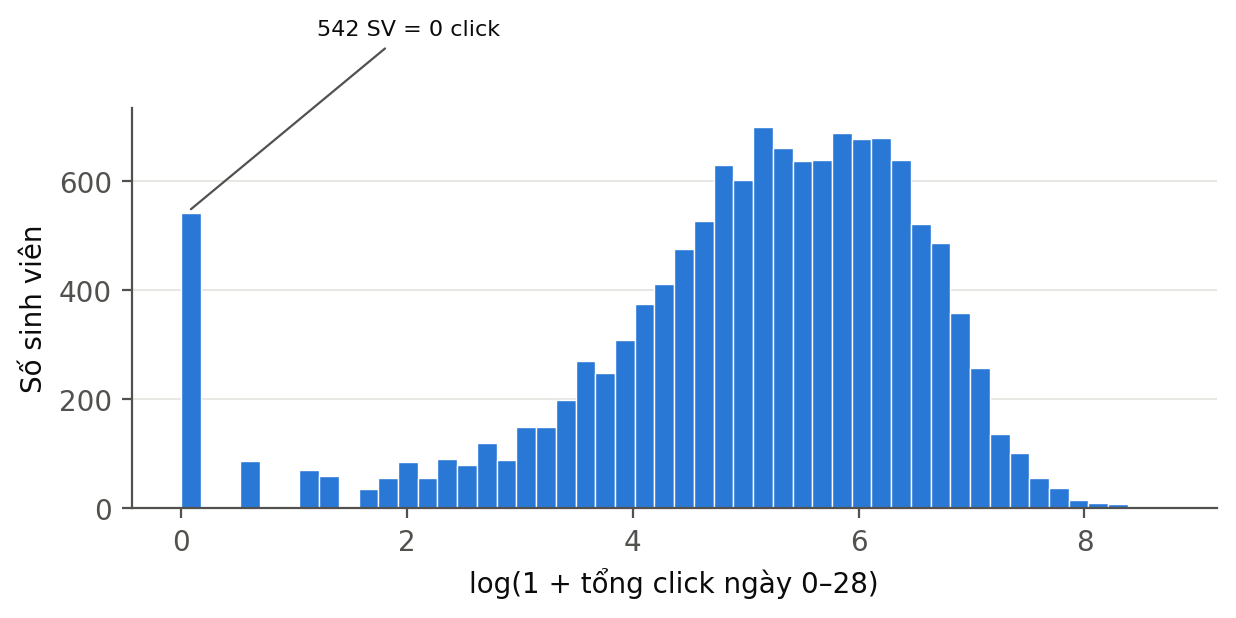

fig6_unregistration_timing.png


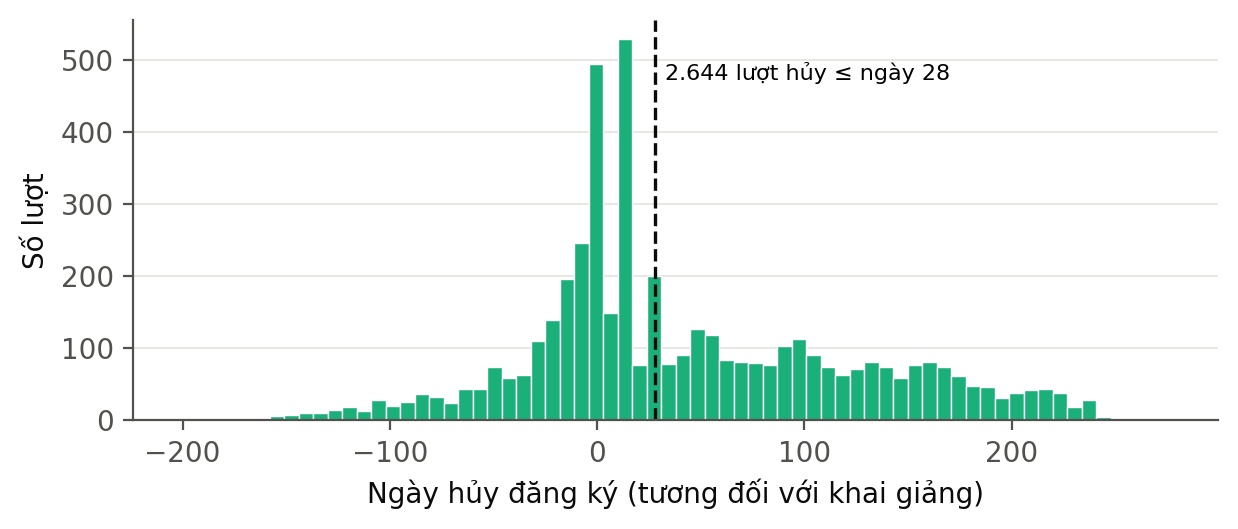

In [8]:
from IPython.display import Image, display
for p in sorted(FIG.glob('fig*.png')): print(p.name); display(Image(str(p), width=650))